<a href="https://colab.research.google.com/github/hig3r/mva/blob/2026/E07/mva_2026_E07_01_Bayesian_Classification_GMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# mva_2026_E07_01_Bayesian_Classification_GMM GMMのベイズ分類

- 学籍番号 [ ]
- 氏名 [ ]

- 訓練データの F1-score [このノートブックには訓練データはない]
- $\pi_0$ [0.6], $\pi_1$ [0.4 ]
- 成分 $y=0$ の毋平均値 [-1]，母共分散行列 [ np.array([[0.8*0.8]]) ]
- 成分 $y=1$ の毋平均値 [2 ]，母共分散行列 [ np.array([[1.2*1.2]]) ]
- $x=-1$ が $y=1$ に分類される確率 [ ]
- $x=-1$ が $y=0$ に分類される確率 [ ]

In [1]:
import numpy as np # 数値計算ライブラリ
import pandas as pd # データ解析ライブラリ
import matplotlib.pyplot as plt # グラフ描画ライブラリ
%matplotlib inline

from sklearn.linear_model import LogisticRegression # scikit-learn のロジスティック回帰
from sklearn.model_selection import train_test_split # scikit-learn の訓練データとテストデータ分割ライブラリ
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

import scipy.stats as stats # 統計ライブラリ

%pip install japanize_matplotlib
import japanize_matplotlib # 日本語フォント

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 8.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for japanize_matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120306 sha256=fcdffdcc1f1a6b335030ef90d65a92d1135397cf00a558c94d8b99d535b615c7
  Stored in directory: /root/.cache/pip/wheels/56/8b/41/7c8a47025c6eef46f0b7488f2510fff13e48f1e7d5bf26e21b
Successfully built japanize_matplotlib


###  既知のGMM

ベイズ分類では，母分布，母数は完全にわかっているとする（GMMの場合に，訓練データからそれらを推定するところから始まるのがQDA)

In [2]:
pi=[0.6,0.4]
mu=[-1,2]
sigma=[0.8,1.2] # 分散でなく標準偏差

In [3]:
rvx=[stats.norm(loc=mu[0], scale=sigma[0]),
     stats.norm(loc=mu[1], scale=sigma[1])]

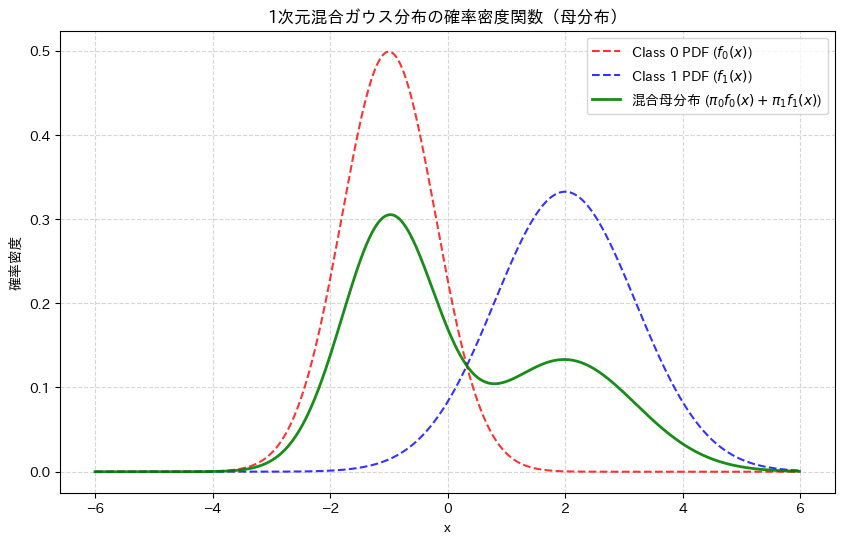

In [4]:
# 1次元用の可視化データ範囲を定義
x_axis = np.arange(-6,6,0.01)

# 各コンポーネント（母分布）のPDFを計算
pdf = [rvx[0].pdf(x_axis),rvx[1].pdf(x_axis)]

pdf_mixture = pi[0] * pdf[0] + pi[1] * pdf[1]

# 描画
plt.figure(figsize=(10, 6))
plt.plot(x_axis, pdf[0], 'r--', label='Class 0 PDF ($f_0(x)$)', alpha=0.8)
plt.plot(x_axis, pdf[1], 'b--', label='Class 1 PDF ($f_1(x)$)', alpha=0.8)
plt.plot(x_axis, pdf_mixture, 'g-', linewidth=2, label=r'混合母分布 ($\pi_0 f_0(x) + \pi_1 f_1(x)$)', alpha=0.9)

plt.title('1次元混合ガウス分布の確率密度関数（母分布）')
plt.xlabel('x')
plt.ylabel('確率密度')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("gmm1d-discr.pdf", format='pdf', bbox_inches='tight')
plt.show()

In [5]:
x_test=-1

In [9]:
# x = -1 における各クラスの確率密度（likelihood）を計算
fx= [rvx[0].pdf(x_test),rvx[1].pdf(x_test)]

# 事前確率 * 尤度 (分子の計算)
post_numerator=[pi[0] * fx[0],pi[1]*fx[1]]

# 混合分布の密度（分母の計算）
post_denominator = post_numerator[0]+post_numerator[1]

# 事後確率の計算
post = post_numerator / post_denominator

print(f"--- x = {x_test} のときの事後確率 ---")
print(f"Class 0 の事後確率 P(y=0|x={x_test}): {post[0]:.6f}")
print(f"Class 1 の事後確率 P(y=1|x={x_test}): {post[1]:.6f}")

# クラスの決定
estimated_class = 0 if post[0] > post[1] else 1
print(f"\n推定されるクラス: Class {estimated_class}")

--- x = -1 のときの事後確率 ---
Class 0 の事後確率 P(y=0|x=-1): 0.980846
Class 1 の事後確率 P(y=1|x=-1): 0.019154

推定されるクラス: Class 0
